## Patient Treatment Outcome Analysis

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
import pandas as pd

patients = pd.read_csv("C:/Users/tanvi jalan/Downloads/patients csv.csv")
admissions = pd.read_csv("C:/Users/tanvi jalan/Downloads/admissions csv.csv")
departments = pd.read_csv("C:/Users/tanvi jalan/Downloads/departments csv.csv")
treatments = pd.read_csv("C:/Users/tanvi jalan/Downloads/treatments csv.csv")
billing = pd.read_csv("C:/Users/tanvi jalan/Downloads/billing csv.csv")
readmissions = pd.read_csv("C:/Users/tanvi jalan/Downloads/readmissions csv.csv")


In [7]:
df = admissions.merge(patients, on='patient_id') \
               .merge(billing, on='admission_id') \
               .merge(readmissions, on='admission_id', how='left') \
               .merge(treatments, on='admission_id', how='left')


In [11]:
# 📌 Required Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# ✅ Merge all tables
df = admissions.merge(patients, on='patient_id') \
               .merge(billing, on='admission_id') \
               .merge(readmissions, on='admission_id', how='left') \
               .merge(treatments, on='admission_id', how='left')

# ✅ Fix: ensure consistent column formatting
df['readmit_within_30_days'] = df['readmit_within_30_days'].fillna('No')
df['readmit_within_30_days'] = df['readmit_within_30_days'].astype(str).str.strip().str.lower()

# ✅ Create a Boolean column for readmission
df['was_readmitted'] = df['readmit_within_30_days'] == 'yes'

# ✅ Confirm column names
print(df.columns.tolist())  # Optional check


['admission_id', 'patient_id_x', 'department', 'admission_date', 'discharge_date', 'length_of_stay', 'outcome', 'name', 'age', 'gender', 'city', 'chronic_conditions', 'billing_id', 'total_cost', 'insurance_covered', 'paid_by_patient', 'readmit_id', 'patient_id_y', 'readmit_within_30_days', 'reason', 'treatment_id', 'treatment_type', 'diagnosis', 'medication', 'was_readmitted']


## KPI 1: AVERAGE TREATMENT COST BY DEPARTMENT

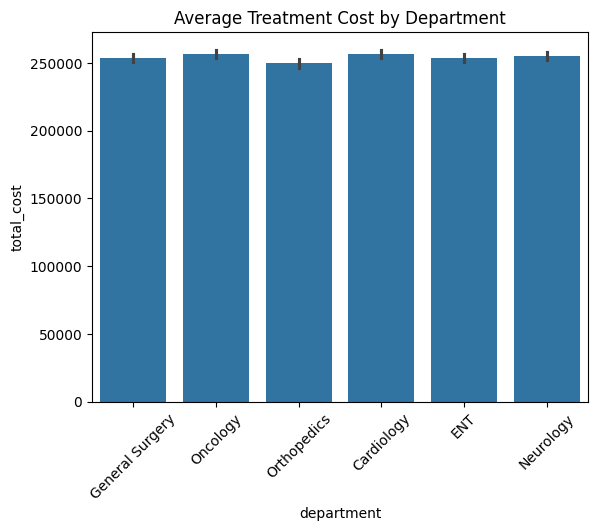

In [9]:
sns.barplot(data=df, x='department', y='total_cost', estimator='mean')
plt.title('Average Treatment Cost by Department')
plt.xticks(rotation=45)
plt.show()


## KPI 2: READMISSION RATE BY DIAGNOSIS

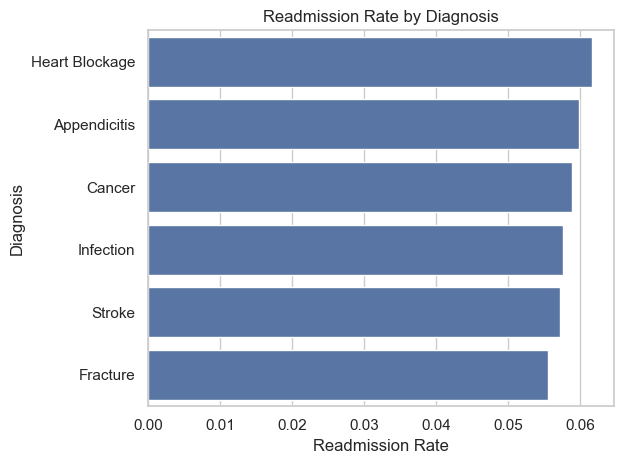

In [13]:
df['readmit_within_30_days'] = df['readmit_within_30_days'].fillna('No')
df['readmit_within_30_days'] = df['readmit_within_30_days'].astype(str).str.strip().str.lower()
df['was_readmitted'] = df['readmit_within_30_days'] == 'yes'

readmit_rate = df.groupby('diagnosis')['was_readmitted'].mean().reset_index()

import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

sns.barplot(
    data=readmit_rate.sort_values('was_readmitted', ascending=False),
    x='was_readmitted',
    y='diagnosis'
)

plt.title("Readmission Rate by Diagnosis")
plt.xlabel("Readmission Rate")
plt.ylabel("Diagnosis")
plt.tight_layout()
plt.show()


## KPI 3: MOST COMMON TREATMENT TYPES

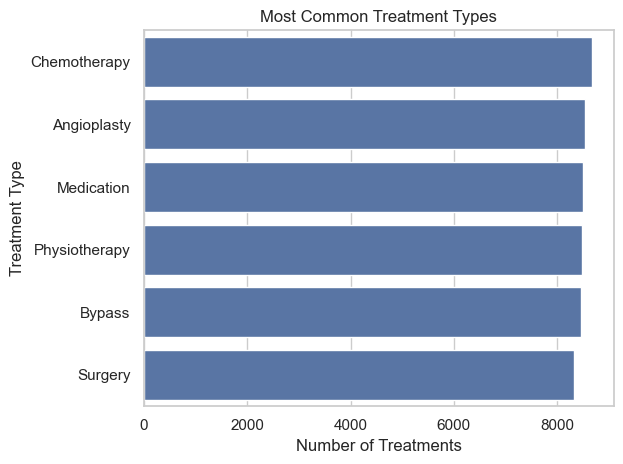

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid")

sns.countplot(data=df, y='treatment_type', order=df['treatment_type'].value_counts().index)
plt.title("Most Common Treatment Types")
plt.xlabel("Number of Treatments")
plt.ylabel("Treatment Type")
plt.tight_layout()
plt.show()


## KPI 4: AVERAGE LENGTH OF STAY BY AGE GROUP

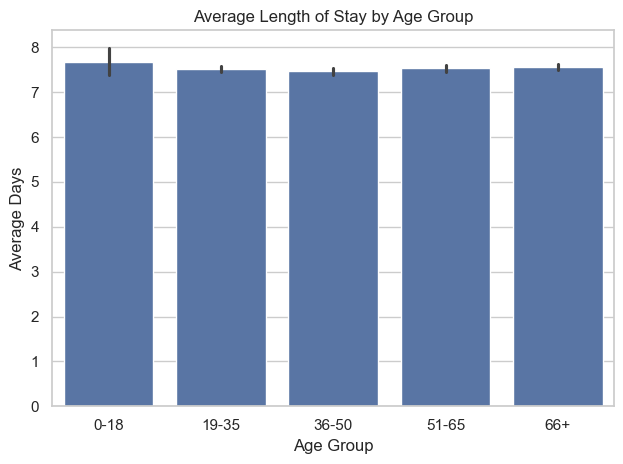

In [15]:
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 35, 50, 65, 100],
                         labels=["0-18", "19-35", "36-50", "51-65", "66+"])

sns.barplot(data=df, x='age_group', y='length_of_stay')
plt.title("Average Length of Stay by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Days")
plt.tight_layout()
plt.show()


## KPI 5: READMISSION RATE BY DEPARTMENT

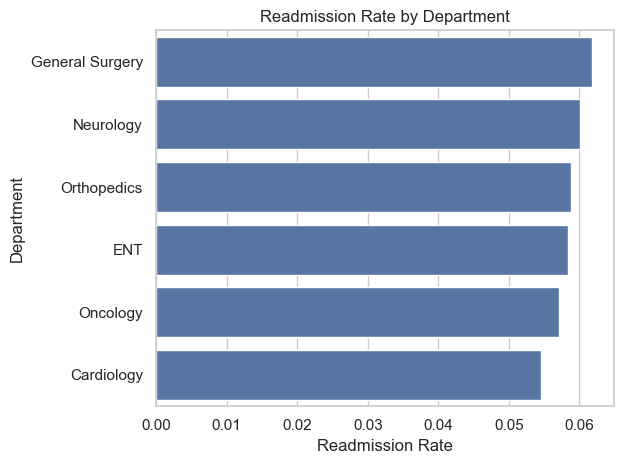

In [16]:
readmit_by_dept = df.groupby('department')['was_readmitted'].mean().reset_index()

sns.barplot(data=readmit_by_dept.sort_values('was_readmitted', ascending=False),
            x='was_readmitted', y='department')
plt.title("Readmission Rate by Department")
plt.xlabel("Readmission Rate")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


## KPI 6: READMISSIONS BY OUTCOME

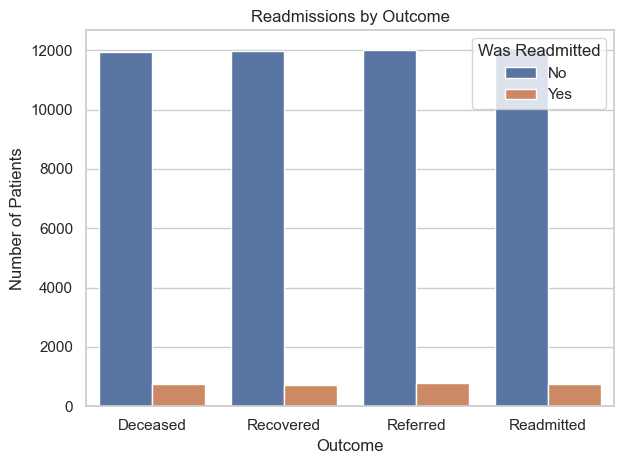

In [17]:
sns.countplot(data=df, x='outcome', hue='was_readmitted')
plt.title("Readmissions by Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.legend(title="Was Readmitted", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


## KPI 7: TREATMENT COST BY OUTCOME

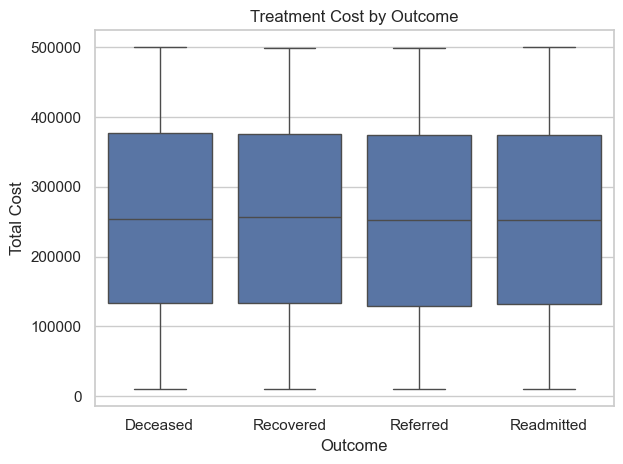

In [18]:
sns.boxplot(data=df, x='outcome', y='total_cost')
plt.title("Treatment Cost by Outcome")
plt.xlabel("Outcome")
plt.ylabel("Total Cost")
plt.tight_layout()
plt.show()


## KPI 8: GENDER VS READMISSIONS

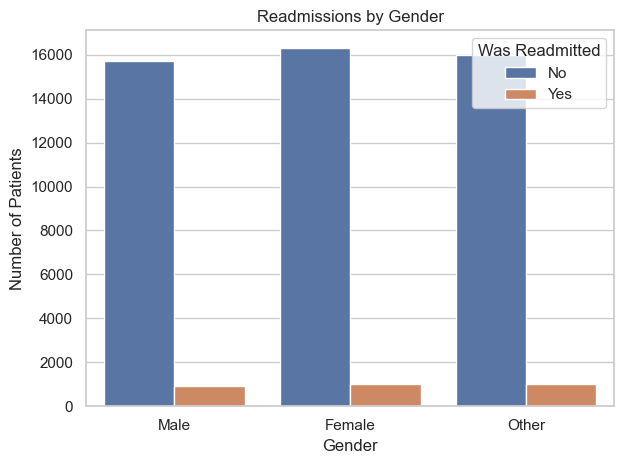

In [19]:
sns.countplot(data=df, x='gender', hue='was_readmitted')
plt.title("Readmissions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.legend(title="Was Readmitted", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


In [20]:
# 📁 Export final merged data
df.to_csv("cleaned_dataset_for_powerbi.csv", index=False)
print("✅ Data exported successfully.")


✅ Data exported successfully.
